In [1]:
import duckdb
con = duckdb.connect()
con.execute("""
CREATE OR REPLACE VIEW events_ord AS
SELECT *, file_row_number AS rn
FROM read_parquet('../data/bpi2019.parquet', file_row_number=true)
WHERE "case:concept:name" NOT IN (
  SELECT DISTINCT "case:concept:name"
  FROM read_parquet('../data/bpi2019.parquet')
  WHERE "time:timestamp" < TIMESTAMPTZ '2017-01-01')
""")

In [2]:
edges = con.sql("""
WITH o AS (
  SELECT "concept:name" AS a, "time:timestamp" AS ts,
    LAG("concept:name") OVER (PARTITION BY "case:concept:name" ORDER BY "time:timestamp", rn) AS pa,
    LAG("time:timestamp") OVER (PARTITION BY "case:concept:name" ORDER BY "time:timestamp", rn) AS pts
  FROM events_ord)
SELECT pa AS src, a AS dst, COUNT(*) AS n,
       ROUND(MEDIAN(date_diff('second', pts, ts)) / 86400.0, 1) AS med_days
FROM o WHERE pa IS NOT NULL GROUP BY 1, 2
""").df()

edges = edges[edges.n >= 5000].sort_values("n", ascending=False)
print(len(edges), "transitions gardées")
edges

25 transitions gardées


,src,dst,n,med_days
451,Record Service Entry Sheet,Record Service Entry Sheet,139103,0.0
200,Record Invoice Receipt,Clear Invoice,134816,36.1
447,Record Goods Receipt,Record Invoice Receipt,112114,12.8
273,Vendor creates invoice,Record Goods Receipt,110131,1.4
473,Create Purchase Order Item,Vendor creates invoice,103142,6.5
475,Vendor creates invoice,Record Invoice Receipt,95169,4.7
478,Record Goods Receipt,Vendor creates invoice,80613,0.6
175,Create Purchase Order Item,Record Goods Receipt,77153,12.8
179,Record Goods Receipt,Record Goods Receipt,54269,0.0
376,Remove Payment Block,Clear Invoice,49419,25.3


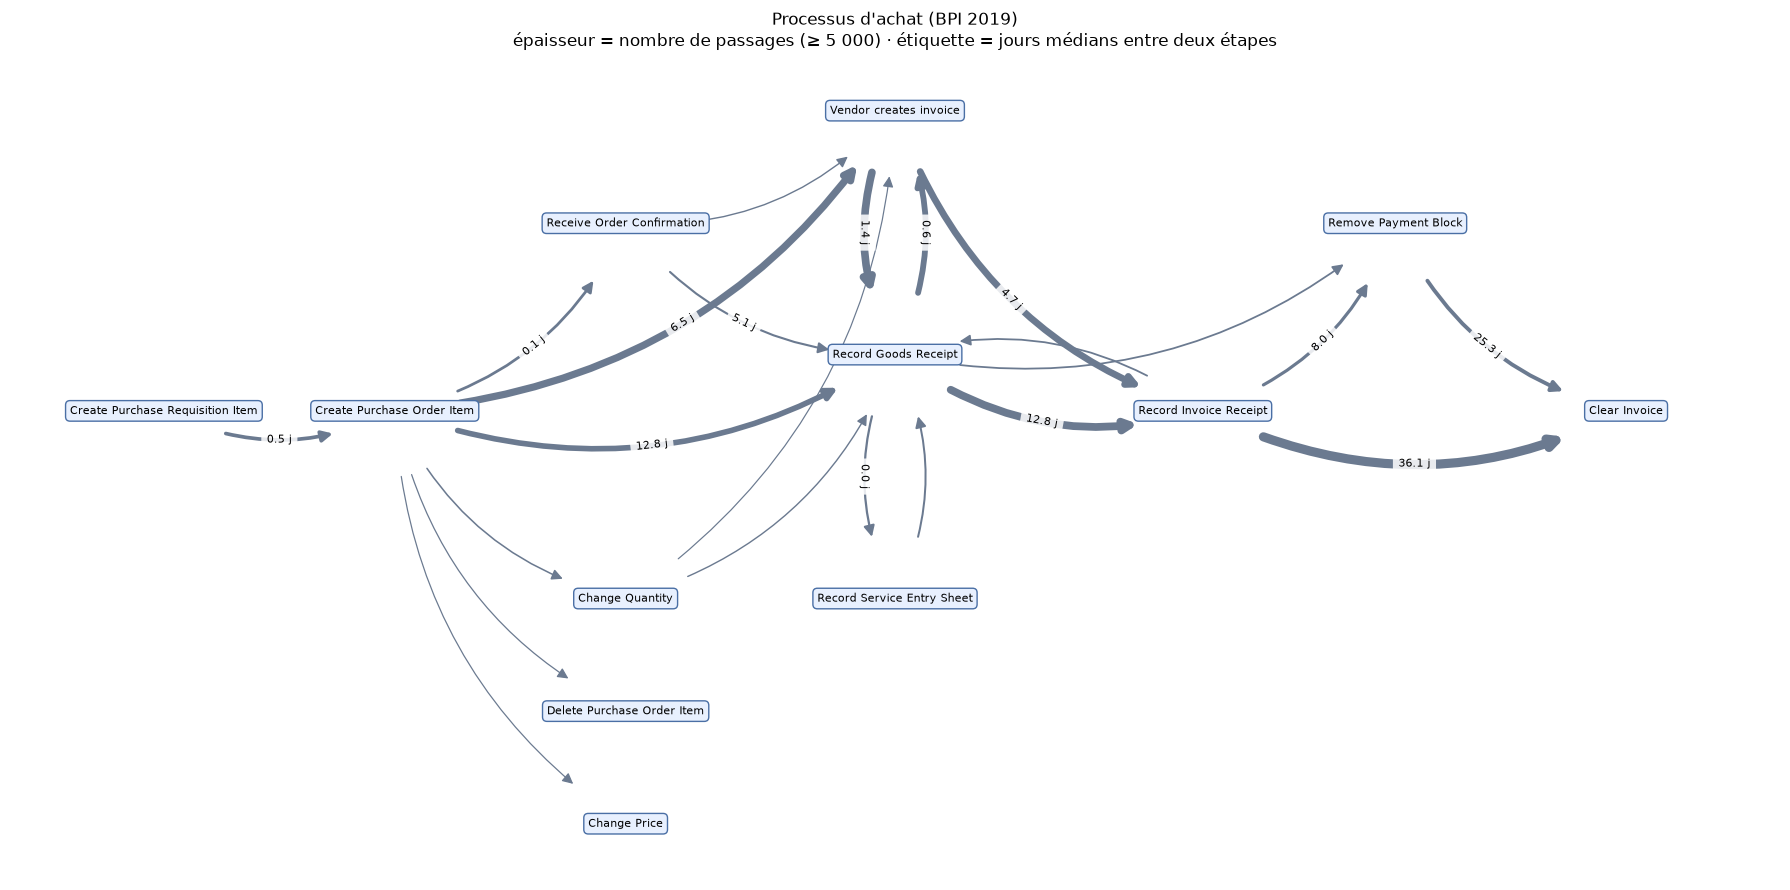

In [6]:
import matplotlib.pyplot as plt
import networkx as nx

# 1) On retire les boucles (A -> A) : on les traitera dans le texte
e = edges[edges.src != edges.dst].copy()

G = nx.DiGraph()
for r in e.itertuples():
    G.add_edge(r.src, r.dst, n=r.n, d=r.med_days)

pos = {
 "Create Purchase Requisition Item": (0, 0),
 "Create Purchase Order Item": (1.2, 0),
 "Receive Order Confirmation": (2.4, 2),
 "Change Quantity": (2.4, -2),
 "Delete Purchase Order Item": (2.4, -3.2),
 "Change Price": (2.4, -4.4),
 "Record Goods Receipt": (3.8, 0.6),
 "Record Service Entry Sheet": (3.8, -2.0),
 "Vendor creates invoice": (3.8, 3.2),
 "Record Invoice Receipt": (5.4, 0),
 "Remove Payment Block": (6.4, 2),
 "Clear Invoice": (7.6, 0),
}

fig, ax = plt.subplots(figsize=(18, 9))
maxn = e.n.max()

# node_size plus petit => les flèches arrivent plus près des boîtes
nx.draw_networkx_edges(
    G, pos, ax=ax,
    width=[0.6 + 6 * d["n"] / maxn for _, _, d in G.edges(data=True)],
    edge_color="#6b7a90", arrows=True, arrowsize=16,
    node_size=4500, node_shape="s",
    connectionstyle="arc3,rad=0.25")

# 2) médiane de jours sur les flèches importantes (> 20 000 passages)
labels = {(u, v): f"{d['d']} j" for u, v, d in G.edges(data=True) if d["n"] > 20000}
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, ax=ax, font_size=8,
                             label_pos=0.5, connectionstyle="arc3,rad=0.25",
                             bbox=dict(fc="white", ec="none", alpha=0.85))

nx.draw_networkx_labels(G, pos, ax=ax, font_size=8,
    bbox=dict(boxstyle="round,pad=0.4", fc="#e8f0fe", ec="#4a6fa5"))

ax.set_title("Processus d'achat (BPI 2019)\n"
             "épaisseur = nombre de passages (≥ 5 000) · étiquette = jours médians entre deux étapes",
             fontsize=12)
ax.set_xlim(-0.8, 8.4); ax.set_ylim(-5, 3.8)
ax.axis("off")
plt.tight_layout()
plt.savefig("../reports/process_map.png", dpi=160)
plt.show()